# 11 · Rung 1: a GRU that only looks at time

**Objective.** Build the simplest honest deep-learning forecaster and ask: *without any road graph, is a neural network better than XGBoost?* This is the deep-learning version of the "independent segment" models in the brief.

**Concept.** A **GRU** (gated recurrent unit) reads a sequence one step at a time and keeps a hidden state `h`. At each step two gates decide how much of the old state to keep and how much new input to write. After 12 steps, `h` summarises the sensor's last hour.

| Design choice | What we did | Why |
|---|---|---|
| one GRU for all 207 sensors | weights shared | 207 separate networks would each see 1/207 of the data |
| sensor embedding (16 numbers) | learned per sensor, joined to `h` | lets the shared GRU specialise, like the sensor-id feature in XGBoost |
| residual target | predict `speed − last observed speed` | the network only has to learn the *change*; a zero output is already persistence |
| direct multi-horizon head | one MLP outputs all 12 steps at once | no error feedback between steps, fast, simple |
| masked MAE loss | missing targets contribute nothing | a sensor outage is not a 0-mph jam |

No sensor ever sees another sensor. Any gain over XGBoost here comes from the model class, not from the network.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}")

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from src import preprocessing as pp, visualization as viz, evaluation as ev
from src.graph_utils import load_graph_artifacts
from deep_learning.dl.data import WindowData
from deep_learning.dl import engine
from deep_learning.dl.models import build

viz.apply_style()
ctx = pp.load_context()
adj = load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids).adjacency
data = WindowData.from_context(ctx, "cpu")
SEEDS = (42, 1, 2)

## 1 · Follow one batch through the network

Printing the shape after every layer is the fastest way to understand (and debug) a model.

In [3]:
model = build("gru", adj, d_model=128)
summary = engine.load_weights(model, config.ARTIFACTS / "models" / "dl_gru_s42.pt")
model.eval()
b = data.batch(data.origins["test"][:8])
enc = model.encoder
with torch.no_grad():
    x = b["x"];                                        print("input x              ", tuple(x.shape), " [B, L, N, F]")
    z = enc.proj(x);                                   print("after Linear(6->128) ", tuple(z.shape))
    z = z.permute(0, 2, 1, 3).reshape(-1, 12, 128);    print("one sequence/sensor  ", tuple(z.shape), "   [B*N, L, d]")
    _, h = enc.gru(z);                                 print("GRU final state      ", tuple(h[-1].shape))
    h = enc(x);                                        print("+ sensor embedding   ", tuple(h.shape), "   [B, N, d]")
    r = model.head(h).permute(0, 2, 1);                print("12 residuals         ", tuple(r.shape), "   [B, H, N]")
    out = model(b);                                    print("anchor + residual    ", tuple(out.shape))
print(f"\nparameters: {engine.count_parameters(model):,}")
for name, p in model.named_parameters():
    print(f"  {name:28s} {str(tuple(p.shape)):14s} {p.numel():>7,}")

input x               (8, 12, 207, 6)  [B, L, N, F]
after Linear(6->128)  (8, 12, 207, 128)
one sequence/sensor   (1656, 12, 128)    [B*N, L, d]
GRU final state       (1656, 128)
+ sensor embedding    (8, 207, 128)    [B, N, d]
12 residuals          (8, 12, 207)    [B, H, N]
anchor + residual     (8, 12, 207)

parameters: 157,948
  encoder.proj.weight          (128, 6)           768
  encoder.proj.bias            (128,)             128
  encoder.gru.weight_ih_l0     (384, 128)      49,152
  encoder.gru.weight_hh_l0     (384, 128)      49,152
  encoder.gru.bias_ih_l0       (384,)             384
  encoder.gru.bias_hh_l0       (384,)             384
  encoder.node_emb.weight      (207, 16)        3,312
  encoder.fuse.weight          (128, 144)      18,432
  encoder.fuse.bias            (128,)             128
  head.0.weight                (256, 128)      32,768
  head.0.bias                  (256,)             256
  head.3.weight                (12, 256)        3,072
  head.3.bias       

**Where do the parameters live?** Most are in the GRU (3 gates × (input + hidden) × 128) and the head. The sensor embedding is only 207 × 16 = 3,312 numbers.

## 2 · Training: three seeds

Each run was trained on a Kaggle T4 with the same recipe as every other model (AdamW, lr 1e-3, masked MAE, early stopping on validation MAE with patience 10). Three seeds tell us how much of a result is luck of initialisation.

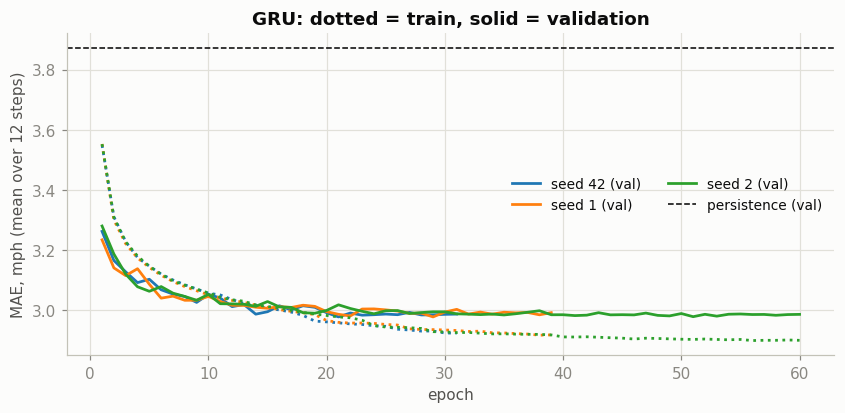

,best epoch,epochs run,best val MAE,s / epoch (T4)
seed,,,,
42,21,31,2.977,34
1,29,39,2.977,34
2,51,60,2.978,34


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
rows = []
for s in SEEDS:
    run = f"dl_gru_s{s}"
    h = pd.read_csv(config.ARTIFACTS / "metrics" / f"{run}_history.csv")
    sm = json.loads((config.ARTIFACTS / "metrics" / f"{run}_summary.json").read_text())
    ax.plot(h.epoch, h.val_mae_mph, label=f"seed {s} (val)")
    ax.plot(h.epoch, h.train_mae_mph, ls=":", c=ax.lines[-1].get_color())
    rows.append({"seed": s, "best epoch": sm["best_epoch"], "epochs run": len(h), "best val MAE": round(sm["best_val_mae_mph"], 3),
                 "s / epoch (T4)": round(h.seconds.mean())})
ax.axhline(3.872, c="k", ls="--", lw=1, label="persistence (val)")
ax.set(xlabel="epoch", ylabel="MAE, mph (mean over 12 steps)", title="GRU: dotted = train, solid = validation")
ax.legend(ncol=2); plt.show()
display(pd.DataFrame(rows).set_index("seed"))

The three seeds land within 0.001 mph of each other on validation. That spread is the yardstick for every comparison later: a difference between models much smaller than the seed spread is not a finding.

## 3 · Test set: GRU against persistence and XGBoost

In [5]:
keys = ["persistence", "xgboost", "xgboost_spatial"] + [f"dl_gru_s{s}" for s in SEEDS]
preds, y, ymask, origins, horizons, _ = ev.load_aligned(keys, "test", ctx.speed, ctx.mask)
valid = ev.common_valid_mask(preds, ymask)
t = ev.metrics_by_horizon(preds, y, valid, horizons)
mae = t.pivot(index="model", columns="horizon_min", values="MAE").loc[keys]
gru = mae.loc[[k for k in keys if k.startswith("dl_gru")]]
table = pd.concat([mae.loc[keys[:3]], pd.DataFrame([gru.mean(), gru.std()], index=["GRU mean of 3 seeds", "GRU seed std"])])
table.columns = [f"MAE @ {c} min" for c in table.columns]
display(table.round(3))

,MAE @ 5 min,MAE @ 15 min,MAE @ 30 min,MAE @ 60 min
persistence,2.816,3.492,4.189,5.347
xgboost,2.310,2.835,3.262,3.685
xgboost_spatial,2.230,2.759,3.182,3.651
GRU mean of 3 seeds,2.316,2.824,3.216,3.610
GRU seed std,0.002,0.001,0.002,0.014


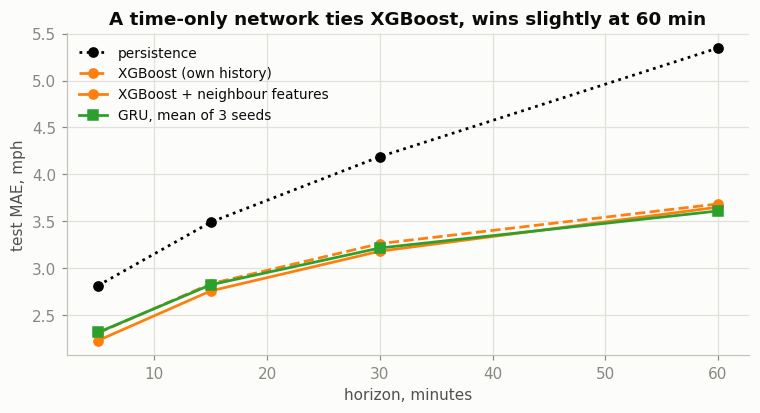

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, style, lab in [("persistence", "k:", "persistence"), ("xgboost", "C1--", "XGBoost (own history)"),
                      ("xgboost_spatial", "C1-", "XGBoost + neighbour features")]:
    ax.plot(mae.columns, mae.loc[k], style, marker="o", label=lab)
ax.plot(mae.columns, gru.mean(), "C2-", marker="s", label="GRU, mean of 3 seeds")
ax.set(xlabel="horizon, minutes", ylabel="test MAE, mph", title="A time-only network ties XGBoost, wins slightly at 60 min")
ax.legend(); plt.show()

## What this rung tells us

* The GRU **ties XGBoost** at 5–15 minutes and is slightly better at 30–60 minutes. Both see only one sensor's own history.
* It is **worse than XGBoost + neighbour features** at short horizons, so information from other sensors matters more than the choice of model class.
* So far, deep learning alone does not justify itself. The question for rung 2 is whether learning *which* neighbours to listen to closes that gap.

## Common mistakes

* **One network per sensor.** 207 tiny models, each trained on 1/207 of the data, over-fit and take 207× longer.
* **Predicting absolute speed.** Without the residual target the network spends its capacity re-learning that speed tomorrow ≈ speed now.
* **Choosing the best seed.** We report the mean and spread of all three, and pick nothing on the test set.

## Check yourself

1. Why does the reshape to `[B*N, L, d]` mean the GRU cannot use other sensors?
2. If the head's final layer were initialised to zero, what would the untrained model predict?
3. Why is the GRU still a *fair* comparison to XGBoost even though it was trained on GPU?